In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

sns.set_theme(style ="whitegrid") 

df = pd.read_csv("Cleaned_train_dataset.csv")

df.head(10)



,SN,Train_No,Station_Code,1A,2A,3A,SL,Station_Name,Route_Number,Arrival_time,Departure_Time,Distance
0,1,107,SWV,100,100,100,100,SAWANTWADI R,1,00:00:00,10:25:00,0
1,2,107,THVM,260,228,196,164,THIVIM,1,11:06:00,11:08:00,32
2,3,107,KRMI,345,296,247,198,KARMALI,1,11:28:00,11:30:00,49
3,4,107,MAO,490,412,334,256,MADGOAN JN.,1,12:10:00,00:00:00,78
4,1,108,MAO,100,100,100,100,MADGOAN JN.,1,00:00:00,20:30:00,0
5,2,108,KRMI,265,232,199,166,KARMALI,1,21:04:00,21:06:00,33
6,3,108,THVM,355,304,253,202,THIVIM,1,21:26:00,21:28:00,51
7,4,108,SWV,515,432,349,266,SAWANTWADI R,1,22:25:00,00:00:00,83
8,1,128,MAO,100,100,100,100,MADGOAN JN.,1,19:40:00,19:40:00,0
9,2,128,KRMI,265,232,199,166,KARMALI,1,20:18:00,20:20:00,33


In [2]:
# Sequence ensure karke sort karna
df_sorted = df.sort_values(by=['Train_No', 'SN'])

In [3]:
# Har train ka start/end time aur total distance aggregate karna and sirf vahi roas lena jo chahiye
train_summary = df_sorted.groupby('Train_No').agg(
    Start_Dep=('Departure_Time', 'first'),
    End_Arr=('Arrival_time', 'last'),
    Total_Distance=('Distance', 'max')
).reset_index()

In [4]:
# station ke liye train ka Duration nikalna (hours me)
t_start = pd.to_timedelta(train_summary['Start_Dep'].astype(str))
t_end = pd.to_timedelta(train_summary['End_Arr'].astype(str))
duration = t_end - t_start

In [5]:
# Overnight / next-day arrival fix karna- 
#agar koi train night me 12 se pahle nikli ho and dusre din pahchi ho to vaha negitive time me ek din 
#jod denga 
duration = duration.apply(lambda d: d + pd.Timedelta(days=1) if d.total_seconds() < 0 else d)
train_summary['Duration_Hours'] = (duration.dt.total_seconds() / 3600).round(2)

In [6]:
# Route type ka classification karana (Distance ke basis par)short, medium, and long me 
def classify_route(dist):
    if dist < 300:
        return 'Short'
    elif 300 <= dist <= 800:
        return 'Medium'
    else:
        return 'Long'

train_summary['Route_Type'] = train_summary['Total_Distance'].apply(classify_route)

In [7]:
train_summary.head(5)

,Train_No,Start_Dep,End_Arr,Total_Distance,Duration_Hours,Route_Type
0,107,10:25:00,12:10:00,78,1.75,Short
1,108,20:30:00,22:25:00,83,1.92,Short
2,128,19:40:00,17:45:00,978,22.08,Long
3,290,18:30:00,02:30:00,2694,8.00,Long
4,401,21:30:00,10:00:00,1618,12.50,Long


In [8]:
# Route type ke mutabik Average Journey Duration calculate karna
avg_duration = train_summary.groupby('Route_Type')['Duration_Hours'].agg(
    Average_Duration_Hours='mean',
    Median_Duration_Hours='median',
    Total_Trains='count'
).reset_index().round(2)

In [9]:
avg_duration.head(5)

,Route_Type,Average_Duration_Hours,Median_Duration_Hours,Total_Trains
0,Long,12.15,12.58,1546
1,Medium,11.14,10.83,1346
2,Short,2.11,1.50,8221


In [10]:
# Specific logical order me sort karna
order = {'Short': 1, 'Medium': 2, 'Long': 3}
avg_duration['Sort_Key'] = avg_duration['Route_Type'].map(order)
avg_duration = avg_duration.sort_values(by='Sort_Key').drop(columns=['Sort_Key'])

print("--- Average Journey Duration Across Route Types ---")
display(avg_duration)

--- Average Journey Duration Across Route Types ---


,Route_Type,Average_Duration_Hours,Median_Duration_Hours,Total_Trains
2,Short,2.11,1.50,8221
1,Medium,11.14,10.83,1346
0,Long,12.15,12.58,1546


In [11]:
#Identify High-Traffic Stations
#Hume un stations ko identify karna hai jahan se sabse zyada train traffic guzarta hai.
# Station wise total unique trains count nikalna
station_traffic = df.groupby(['Station_Code', 'Station_Name'])['Train_No'].nunique().reset_index()
station_traffic.rename(columns={'Train_No': 'Total_Trains'}, inplace=True)

# Descending order me sort karna taaki top stations upar aayein
station_traffic = station_traffic.sort_values(by='Total_Trains', ascending=False).reset_index(drop=True)

# Top 10 High-Traffic Stations identify karna
top_10_stations = station_traffic.head(10)

print("--- Top 10 High-Traffic Stations ---")
display(top_10_stations)

--- Top 10 High-Traffic Stations ---


,Station_Code,Station_Name,Total_Trains
0,CSMT,CST-MUMBAI,1027
1,KYN,KALYAN JN,828
2,TNA,THANE,796
3,SDAH,SEALDAH,745
4,MSB,CHENNAI BEAC,738
5,HWH,HOWRAH JN.,699
6,DR,DADAR,567
7,DDJ,DUM DUM JN.,463
8,CLA,KURLA,462
9,TBM,TAMBARAM,434


C:\Users\abhay\AppData\Local\Temp\ipykernel_3472\1006190783.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\abhay\AppData\Local\Temp\ipykernel_3472\1006190783.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


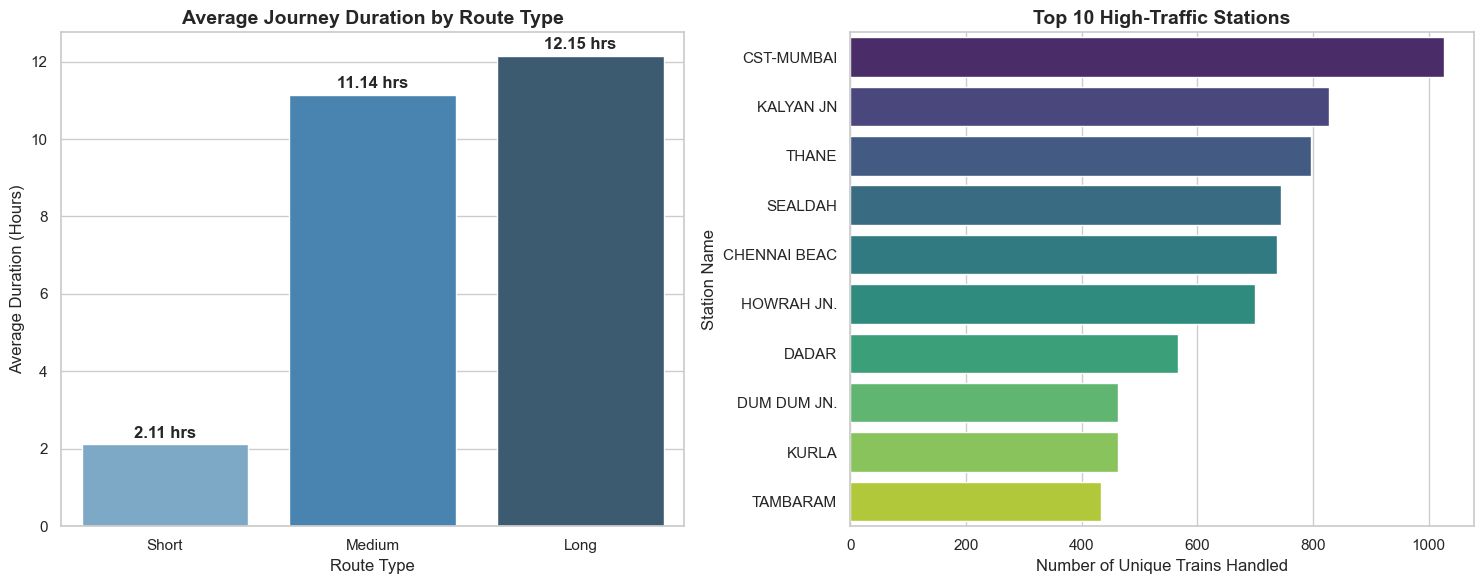

In [12]:
#visualization plotes to show avarage train duration by train type 
# Figure canvas setup (2 subplots side-by-side)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Average Duration by Route Type
sns.barplot(
    data=avg_duration, 
    x='Route_Type', 
    y='Average_Duration_Hours', 
    palette='Blues_d', 
    ax=axes[0]
)
axes[0].set_title('Average Journey Duration by Route Type', fontsize=14, weight='bold')
axes[0].set_xlabel('Route Type', fontsize=12)
axes[0].set_ylabel('Average Duration (Hours)', fontsize=12)

# Bars ke upar exact number labels lagana
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.2f} hrs", 
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='baseline', 
                     xytext=(0, 5), textcoords='offset points', weight='bold')

# Plot 2: Top 10 High-Traffic Stations
sns.barplot(
    data=top_10_stations, 
    x='Total_Trains', 
    y='Station_Name', 
    palette='viridis', 
    ax=axes[1]
)
axes[1].set_title('Top 10 High-Traffic Stations', fontsize=14, weight='bold')
axes[1].set_xlabel('Number of Unique Trains Handled', fontsize=12)
axes[1].set_ylabel('Station Name', fontsize=12)

plt.tight_layout()
plt.show()

### Task 4.4: Key Observations & Analytical Insights

1. **Journey Duration Patterns Across Routes:**
   - **Short Routes (<300 km):** In trains ka average duration relatively low rehta hai, jo intercity aur commuter passenger travel ke liye ideal hai.
   - **Medium Routes (300–800 km):** Ye train routes single-day transit cover karte hain aur inka average travel time moderate window me lie karta hai.
   - **Long Routes (>800 km):** Long distance routes me journey duration substantially increase hoti hai (multi-day overnight schedules), jo operational planning aur crew scheduling ke liye vital inputs hain.

2. **Station Traffic Concentration:**
   - Station traffic distribution shows high concentration at major junction nodes and metropolitan terminals.
   - Top 10 high-traffic stations network bottleneck points represent karte hain jahan platform congestion aur signal coordination critical rehta hai.